In [1]:
import os
import matplotlib.pyplot as plt
import numpy as np
import torch
import corner
import uproot
import pandas as pd
import subprocess

from torch.utils.data import Dataset, DataLoader, random_split

In [2]:
# returns the serial number of the gpu with most free memory
def get_free_gpu():
    result = subprocess.run(
        ["nvidia-smi", "--query-gpu=memory.free", "--format=csv,noheader,nounits"],
        capture_output=True, text=True
    )
    free_mem = [int(x) for x in result.stdout.strip().split("\n")]
    best_gpu = free_mem.index(max(free_mem))
    print(f"Selected GPU {best_gpu} ({free_mem[best_gpu]} MiB free)")
    return best_gpu

In [3]:
# If running on Apple Silicon or CUDA is available, use the GPU.

if torch.backends.mps.is_available():
    device = "mps"
elif torch.cuda.is_available():
    device = "cuda"
    current_device_number = get_free_gpu()
    torch.cuda.set_device(current_device_number)
else:
    device = "cpu"

Selected GPU 0 (40461 MiB free)


### Data loading and preprocessing for training
Import Data

In [4]:
# Get the absolute path of the directory where the notebook is located
cwd = os.getcwd()
print("Current working directory", cwd)
data_folder = os.path.dirname(os.path.dirname(cwd))
data_folder = os.path.join(data_folder, '0_test_exercise')
file_name = os.path.join(data_folder, 'ntuple.18192176.0.root')

with uproot.open(file_name) as file:
    key = file.keys()[0]
    tree = uproot.open(f"{file_name}:" + key)
    print("File opened successfully!")
    print(f"Available classes: {file.classnames()}")
    print(f"Imported Class: {key}")
    print(f"Tree information: {tree}")

Current working directory /scratch/users/yinya/1.0_toy_model/1.0_toy_model
File opened successfully!
Available classes: {'susy;1': 'TTree'}
Imported Class: susy;1
Tree information: <TTree 'susy' (1536 branches) at 0x7fec4b8a3dd0>


Select Branches

In [5]:
theory_param = [branch for branch in tree.keys() if branch.startswith('IN')]
# measure_param = [branch for branch in tree.keys() if branch.startswith('SP')]

Build Trees and remove unnecessary branches (branch with constant values)

In [6]:
def split_constant_nonconstant_columns(df: pd.DataFrame, return_names = False):
    """
    Splits a DataFrame into:
    - constant_df: columns where all values are identical
    - nonconstant_df: columns where at least one value differs
    """
    
    # A column is constant if it has exactly one unique value
    constant_columns = df.nunique(dropna=False) == 1
    
    constant_df = df.loc[:, constant_columns]
    nonconstant_df = df.loc[:, ~constant_columns]
    
    if return_names:
        return constant_df.columns, nonconstant_df.columns
    else:
        return constant_df, nonconstant_df

In [7]:
theory_tree = tree.arrays(theory_param, library='pd')
_, theory_param_nonconst = split_constant_nonconstant_columns(theory_tree, return_names=True)
del theory_tree

# measure_tree = tree.arrays(measure_param, library='pd')
# _, measure_param_nonconst = split_constant_nonconstant_columns(measure_tree, return_names=True)
# del measure_tree

In [8]:
parameters = tree.arrays(theory_param_nonconst, library='pd').astype(np.float32)
mo_omega = tree['MO_Omega'].array(library="np").astype(np.float32)
mo_omega = mo_omega[:, None] #This is to prevent tensor dimension conflict when calculating loss

In [9]:
#We get rid of the samples where mo_omega is -1
mask = (mo_omega != -1).flatten()
parameters = parameters[mask]
mo_omega = mo_omega[mask]

To make training easy for the normalizing flow, we standardize the parameters:

In [10]:
parameters_mean = np.mean(parameters, axis=0)
parameters_std = np.std(parameters, axis=0)

parameters_standardized = (parameters - parameters_mean) / parameters_std

In [11]:
type(mo_omega[0, 0])

numpy.float32

In [12]:
type(parameters_standardized.iloc[0]['IN_M_1'])

numpy.float32

In [13]:
class pMSSM_Dataset(Dataset):
    def __init__(self, parameters, observables):
        self.parameters = parameters
        self.observables = observables

    def __len__(self):
        return len(self.parameters)

    def __getitem__(self, idx):
        params = self.parameters.iloc[idx]
        signal = self.observables[idx]
        
        # Add unit normal noise to the signal
        # noise = np.random.normal(size = signal.shape).astype(np.float32)
        # data = signal + noise
        data = signal
        if device == "mps":
            return torch.tensor(data, dtype=torch.float32, device=device), torch.tensor(params,  dtype=torch.float32, device=device)
        else:
            return torch.tensor(data, device=device), torch.tensor(params, device=device)
    
mo_omega_dataset = pMSSM_Dataset(parameters_standardized, mo_omega)

In [20]:
a, b = mo_omega_dataset[0]
id(a.device)

/tmp/ipykernel_885958/3392773607.py:20: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  return torch.tensor(data, device=device), torch.tensor(params, device=device)


140652553321840

In [23]:
id(device)

140656988135088

Visualize the data $d$ from an arbitrary sample of the `pMSSM_dataset`.

In [15]:
# Get first sample
signal, params = mo_omega_dataset[0]
signal = signal.cpu()  # Careful to put data back onto CPU.
print(signal)
print(params)

tensor([86.7000])
tensor([ 0.5485,  1.1125, -0.5387,  1.2056, -0.5841,  0.3705,  1.2141, -1.0644,
         0.1646,  0.4739,  0.3704, -0.2141], device='cuda:0')


/tmp/ipykernel_885958/3392773607.py:20: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  return torch.tensor(data, device=device), torch.tensor(params, device=device)


### Split data into train and test dataset
Determine the number of training and test samples from a `train_fraction` and use the function `random_split()` to separate the data into a training and test dataset. Afterwards define the training and test dataloaders.

In [16]:
num_samples = len(mo_omega_dataset)
train_fraction = 0.8
num_train = int(round(train_fraction * num_samples))
num_test = num_samples - num_train
train_dataset, test_dataset = random_split(mo_omega_dataset, [num_train, num_test])

# The DataLoader is used in training
train_dataloader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_dataloader = DataLoader(test_dataset, batch_size=64, shuffle=False)

In [17]:
a, b = mo_omega_dataset[0]
a.device

/tmp/ipykernel_885958/3392773607.py:20: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  return torch.tensor(data, device=device), torch.tensor(params, device=device)


device(type='cuda', index=0)

### Conditional Normalizing Flow
We use the `glasflow` library. It is a wrapper for [`nflows`](https://github.com/bayesiains/nflows), which implements different flow types (e.g. autoregressive flows and coupling flows) and transforms (e.g. rational-quadratic splines).


In [18]:

from glasflow.nflows import transforms, distributions, flows
import glasflow.nflows as nflows
import glasflow.nflows.nn.nets as nflows_nets

device = 'cpu'  # For some reason, "mps" does not work here.

In [19]:
a, b = mo_omega_dataset[0]
a.device

/tmp/ipykernel_885958/3392773607.py:20: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  return torch.tensor(data, device=device), torch.tensor(params, device=device)


device(type='cpu')

THe Code is adapted from examples in the [neural spline flow repository](https://github.com/bayesiains/nsf).

First, we define a function that creates the basic MAF or RQS-coupling transform:

In [17]:
def create_base_transform(
    i: int,
    param_dim: int,
    context_dim: int = None,
    hidden_dim: int = 512,
    num_transform_blocks: int = 2,
    batch_norm: bool = False,
    base_transform_type: str = "rq-coupling",
):
    
    activation_fn = torch.nn.ELU()

    if base_transform_type == "maf":
        return transforms.MaskedAffineAutoregressiveTransform(
            param_dim,
            hidden_features=hidden_dim,
            context_features=context_dim,
            num_blocks=num_transform_blocks,
            activation=activation_fn,
            use_batch_norm=batch_norm,
        )
    elif base_transform_type == "rq-coupling":
        if param_dim == 1:
            mask = torch.tensor([1], dtype=torch.uint8)
        else:
            mask = nflows.utils.create_alternating_binary_mask(
                param_dim, even=(i % 2 == 0)
            )
        return transforms.PiecewiseRationalQuadraticCouplingTransform(
            mask=mask,
            transform_net_create_fn=(
                lambda in_features, out_features: nflows_nets.ResidualNet(
                    in_features=in_features,
                    out_features=out_features,
                    hidden_features=hidden_dim,
                    context_features=context_dim,
                    num_blocks=num_transform_blocks,
                    activation=activation_fn,
                    use_batch_norm=batch_norm,
                )
            ),
            num_bins=8,
            tails="linear",
            tail_bound=1.0,
            apply_unconditional_transform=False,
        )

    else:
        raise ValueError

Next, we need to define a transform the randomly permutes the dimensions to ensure that all dimensions interact sufficiently with each other:

In [ ]:
def create_linear_transform(param_dim: int):
    return transforms.CompositeTransform(
        [
            transforms.RandomPermutation(features=param_dim),
            transforms.LULinear(param_dim, identity_init=True),
        ]
    )

Finally, we can define the `create_transform` function which composes a list of `num_flow_steps` transforms where each transform consists of a linear transform (to permute dimensions) and a base transform (MAF or RQ-coupling).
We start and finish the transforms with a linear transform that ensures that the flow outputs samples that have the correct dimensionality (`param_dim`).

In [19]:
def create_transform(
    num_flow_steps: int, 
    param_dim: int, 
    context_dim: int, 
    base_transform_kwargs: dict
):
    return transforms.CompositeTransform(
        [
            transforms.CompositeTransform(
                [
                    create_linear_transform(param_dim),
                    create_base_transform(
                        i, param_dim, context_dim=context_dim, **base_transform_kwargs
                    ),
                ]
            )
            for i in range(num_flow_steps)
        ]
        + [create_linear_transform(param_dim)]
    )

The entire flow model consists of a standard normal base distribution, followed by the flow transform.

In [ ]:
transform = create_transform(num_flow_steps = 3,
                             param_dim = np.shape(parameters)[-1],
                             context_dim = np.shape(mo_omega)[-1], #np.shape(data) instead of data.shape to avoid error by one-dim array
                             base_transform_kwargs = {"base_transform_type": "rq-coupling"})

base_distribution = distributions.StandardNormal(shape=[parameters.shape[-1]])

model = flows.Flow(transform, base_distribution)
model.to(device)

### Training

TODO: If the data is saved as float64, there is an error double!=float. Must I sacrifice my precision?

In [21]:
# Training and test loops

def train_loop(dataloader, model, optimizer):

    model.train()
 
    size = len(dataloader.dataset)
    train_loss = 0
    
    for batch, (X, y) in enumerate(dataloader):
        # Compute negative log probability loss
        loss = - model.log_prob(y, X)
        
        train_loss += loss.detach().sum()
        loss = loss.mean()

        # Backpropagation
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        if batch % 50 == 0:
            loss, current = loss.item(), batch * len(X)
            print(f"Loss: {loss:>7f}  [{current:>5d}/{size:>5d} samples]")
            
    average_loss = train_loss.item() / size
    print('Average loss: {:.4f}'.format(average_loss))
    return average_loss

        
def test_loop(dataloader, model):

    model.eval()
    
    size = len(dataloader.dataset)
    test_loss = 0

    with torch.no_grad():
        for X, y in dataloader:
            loss = - model.log_prob(y, X)
            test_loss += loss.sum()

    test_loss = test_loss.item() / size
    print(f"Test loss: {test_loss:>8f} \n")
    return test_loss

In [24]:
a, b = mo_omega_dataset[0]
a.device

/tmp/ipykernel_884631/3392773607.py:20: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  return torch.tensor(data, device=device), torch.tensor(params, device=device)


device(type='cpu')

In [22]:
optimizer = torch.optim.Adam(model.parameters(), lr=1e-5, weight_decay=1e-5)

epochs = 2
train_history = []
test_history = []
for t in range(epochs):
    print(f"Epoch {t+1}\n-------------------------------")
    loss = train_loop(train_dataloader, model, optimizer)
    train_history.append(loss)
    loss = test_loop(test_dataloader, model)
    test_history.append(loss)
print("Done!")

Epoch 1
-------------------------------


/tmp/ipykernel_884631/3392773607.py:20: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  return torch.tensor(data, device=device), torch.tensor(params, device=device)


Loss: 17.984179  [    0/ 7686 samples]
Loss: 22.630629  [ 3200/ 7686 samples]
Loss: 18.108023  [ 6400/ 7686 samples]
Average loss: 22.0540
Test loss: 19.938736 

Epoch 2
-------------------------------
Loss: 19.787043  [    0/ 7686 samples]
Loss: 19.672413  [ 3200/ 7686 samples]
Loss: 18.550999  [ 6400/ 7686 samples]
Average loss: 19.1237
Test loss: 18.285882 

Done!


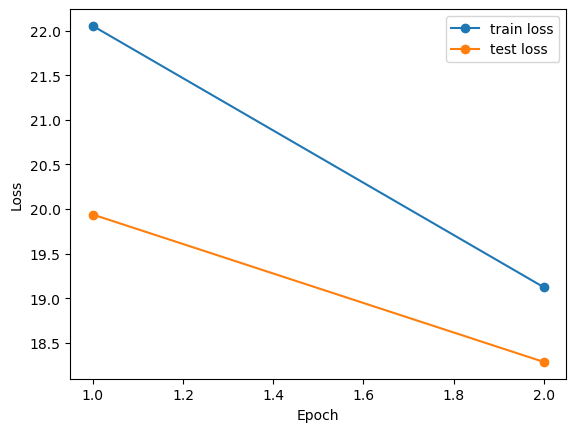

In [23]:
epochs = np.arange(1, len(train_history) + 1)
plt.plot(epochs, train_history, '-o', label = 'train loss')
plt.plot(epochs, test_history, '-o', label = 'test loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [ ]:
# np.save('train_history.npy', train_history)
# np.save('test_history.npy', test_history)

### Visualize posteriors

In [25]:
text_x, _ = test_dataset[0]
text_x.expand??

/tmp/ipykernel_3179451/394356444.py:20: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  return torch.tensor(data, device=device), torch.tensor(params, device=device)


Docstring:
expand(*sizes) -> Tensor

Returns a new view of the :attr:`self` tensor with singleton dimensions expanded
to a larger size.

Passing -1 as the size for a dimension means not changing the size of
that dimension.

Tensor can be also expanded to a larger number of dimensions, and the
new ones will be appended at the front. For the new dimensions, the
size cannot be set to -1.

Expanding a tensor does not allocate new memory, but only creates a
new view on the existing tensor where a dimension of size one is
expanded to a larger size by setting the ``stride`` to 0. Any dimension
of size 1 can be expanded to an arbitrary value without allocating new
memory.

Args:
    *sizes (torch.Size or int...): the desired expanded size

.. warning::

    More than one element of an expanded tensor may refer to a single
    memory location. As a result, in-place operations (especially ones that
    are vectorized) may result in incorrect behavior. If you need to write
    to the tensors, ple

/tmp/ipykernel_3179451/394356444.py:20: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  return torch.tensor(data, device=device), torch.tensor(params, device=device)
/scratch/users/yinya/1.0_toy_model/.pixi/envs/default/lib/python3.11/site-packages/corner/core.py:846: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  if xs[k1] is not None:
/scratch/users/yinya/1.0_toy_model/.pixi/envs/default/lib/python3.11/site-packages/corner/core.py:847: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To a

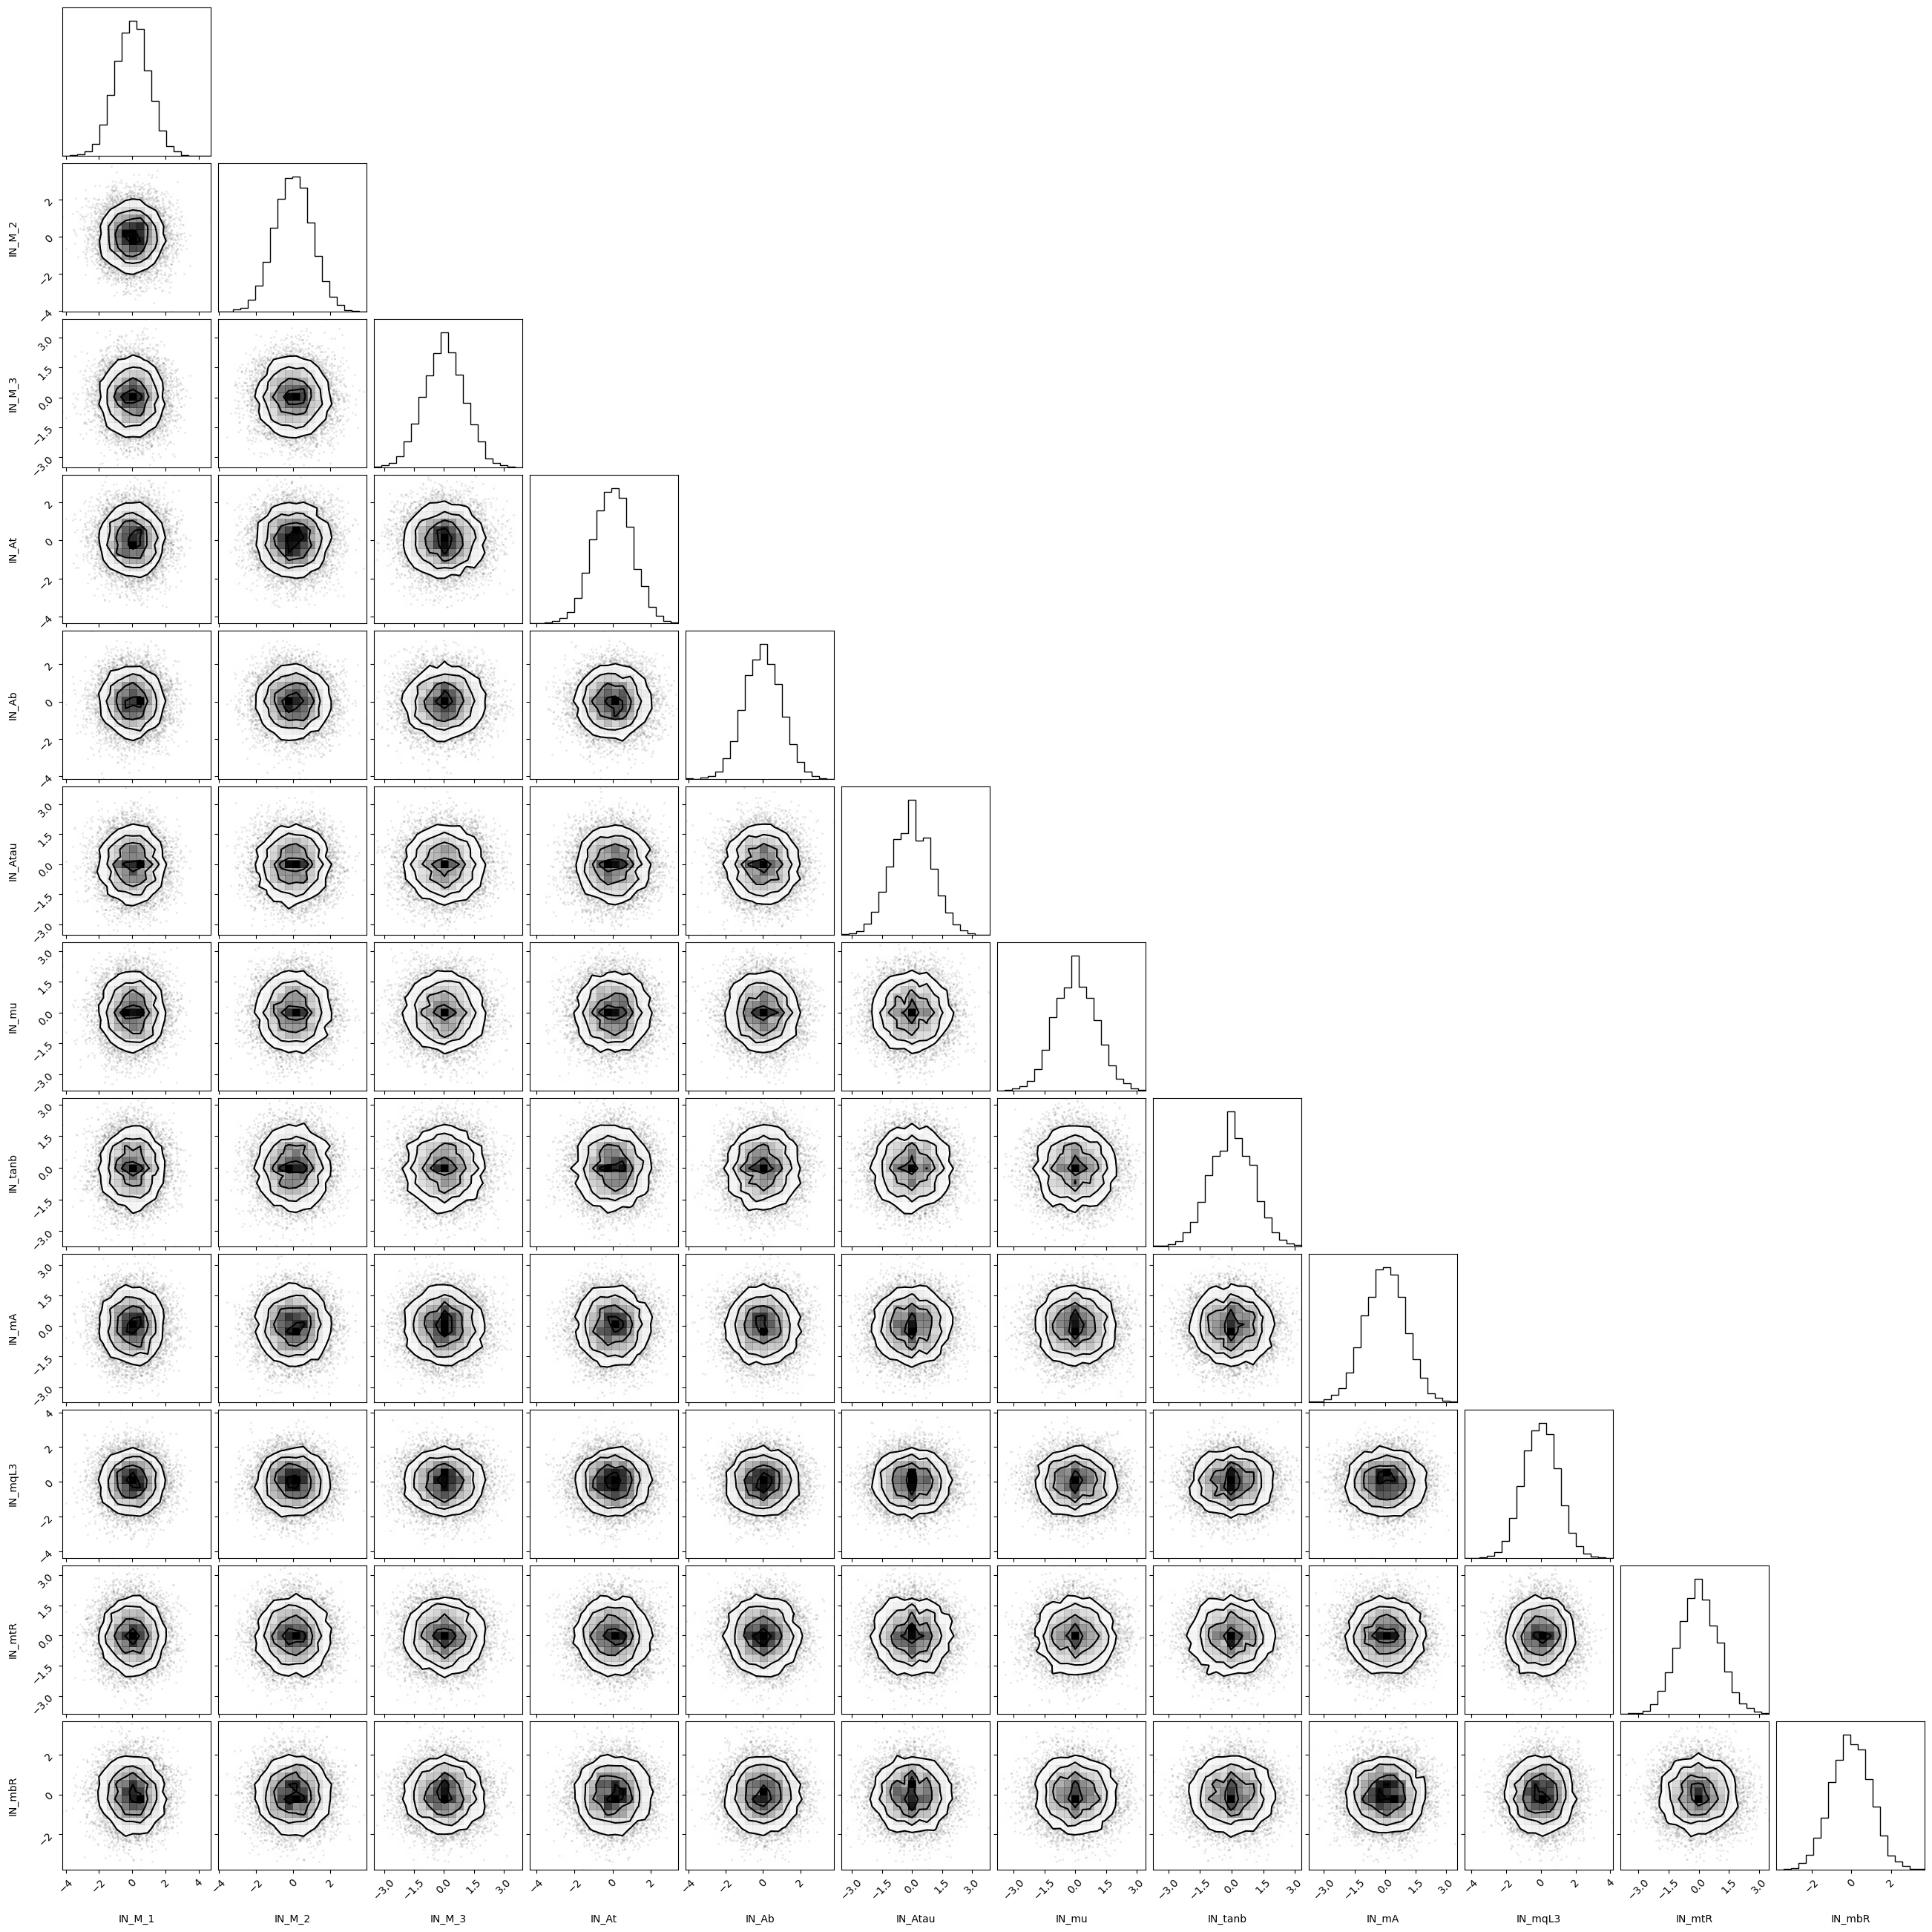

/tmp/ipykernel_3179451/394356444.py:20: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  return torch.tensor(data, device=device), torch.tensor(params, device=device)
/scratch/users/yinya/1.0_toy_model/.pixi/envs/default/lib/python3.11/site-packages/corner/core.py:846: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  if xs[k1] is not None:
/scratch/users/yinya/1.0_toy_model/.pixi/envs/default/lib/python3.11/site-packages/corner/core.py:847: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To a

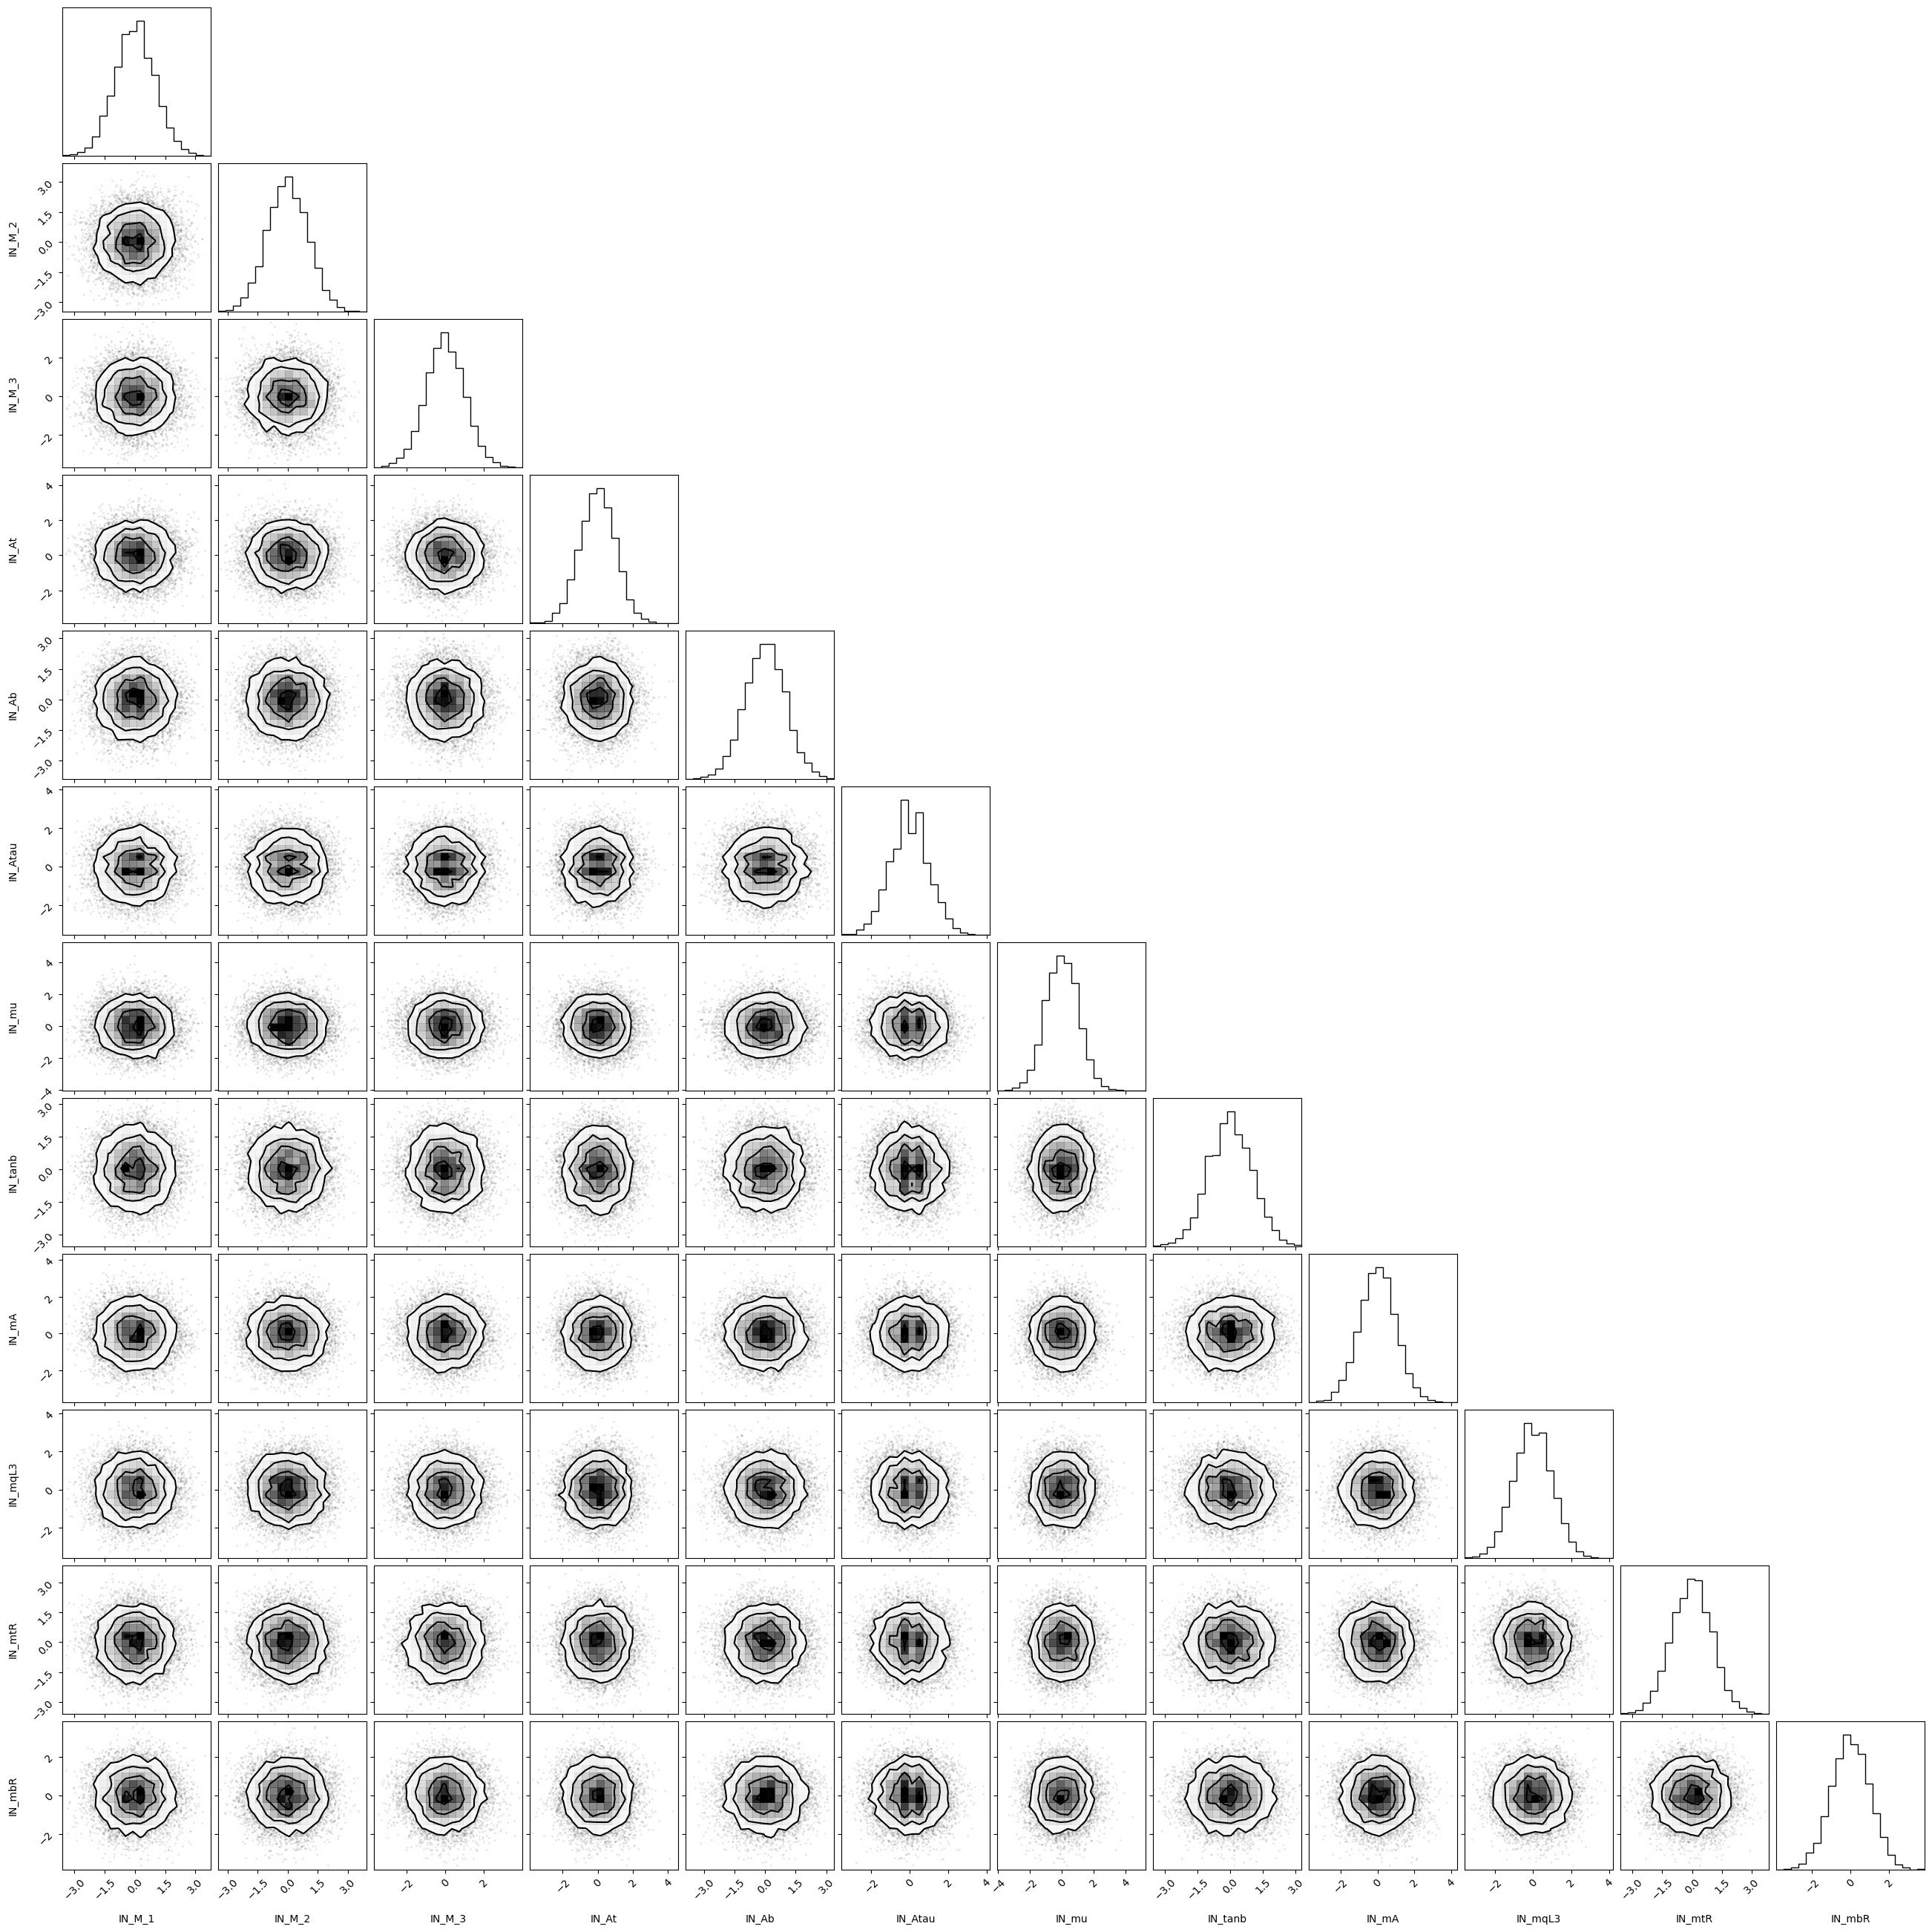

/tmp/ipykernel_3179451/394356444.py:20: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  return torch.tensor(data, device=device), torch.tensor(params, device=device)
/scratch/users/yinya/1.0_toy_model/.pixi/envs/default/lib/python3.11/site-packages/corner/core.py:846: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  if xs[k1] is not None:
/scratch/users/yinya/1.0_toy_model/.pixi/envs/default/lib/python3.11/site-packages/corner/core.py:847: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To a

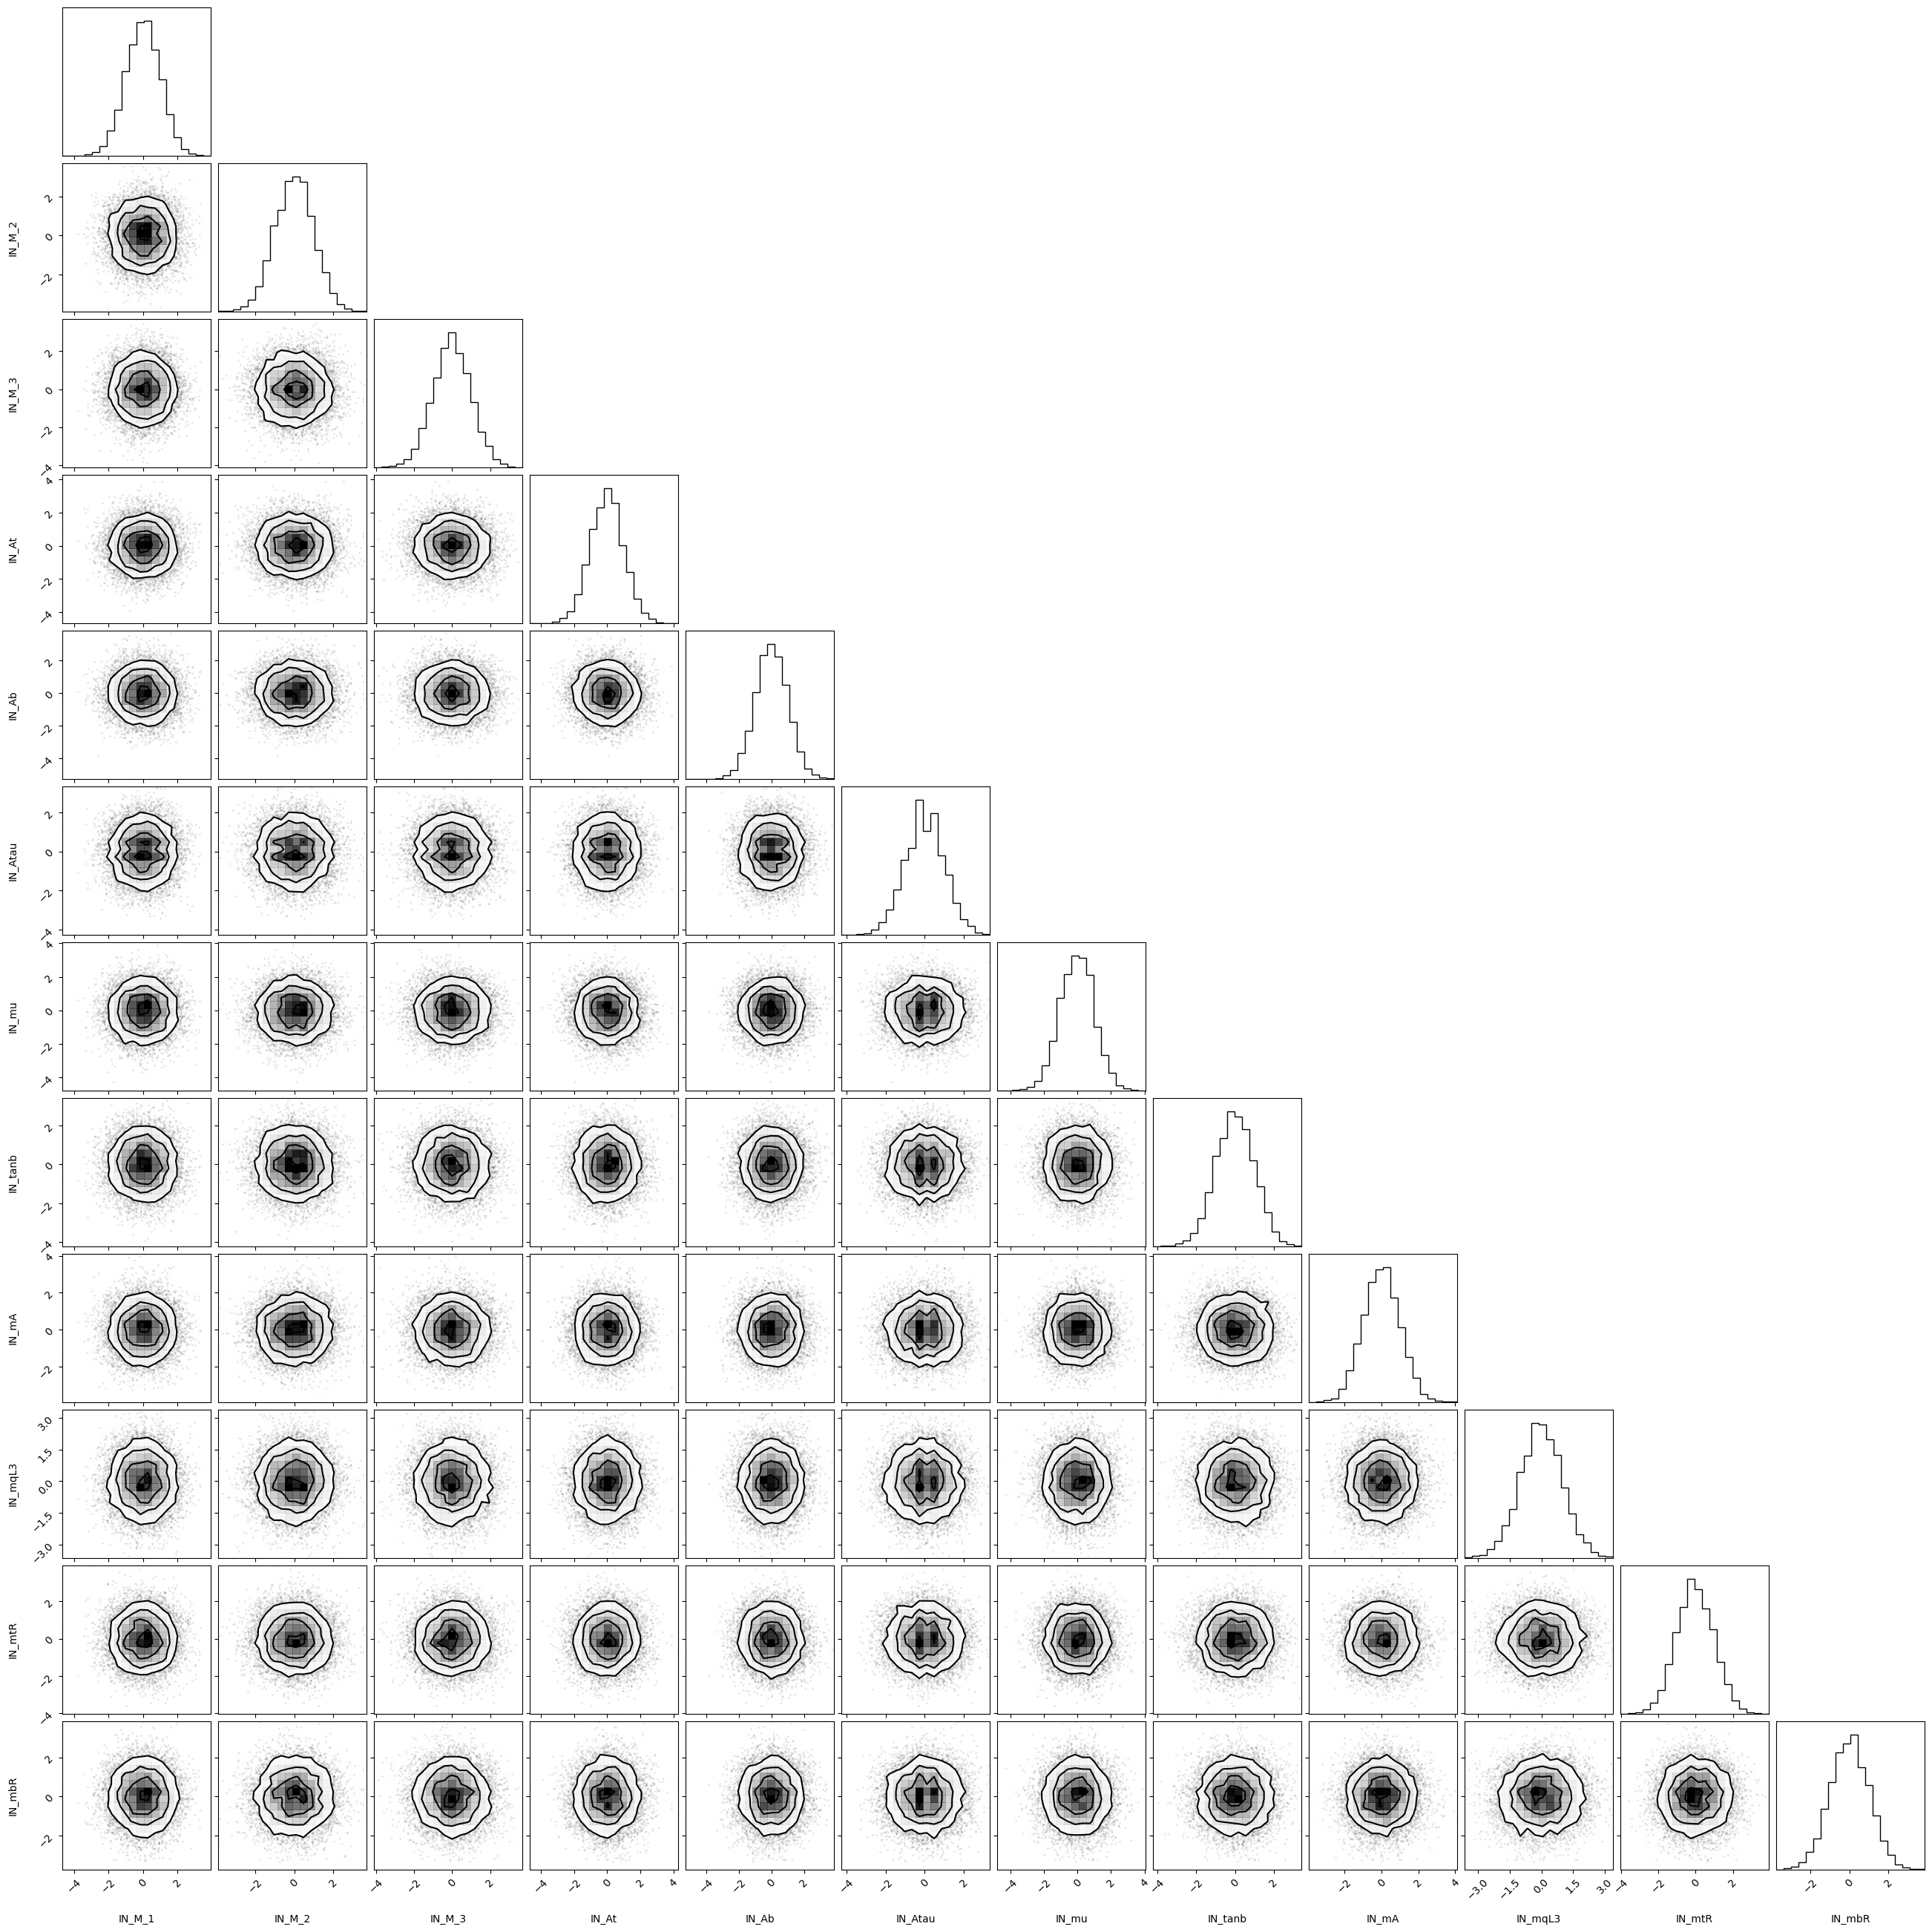

In [26]:
num_posteriors = 3
num_eval_samples = 10_000

model.eval()

for n in range(num_posteriors):

    with torch.no_grad():
    
        test_x, test_y = test_dataset[n]
    
        # Sample the posterior
        test_x = test_x.expand(num_eval_samples, *test_x.shape)
        pred_samples = model.sample(1, test_x).squeeze(1).cpu().numpy()
    
        # Undo the standardization
        truth = parameters_std * test_y.cpu().numpy() + parameters_mean
    
        # Plot
        corner.corner(pred_samples, truths=truth, labels=theory_param_nonconst)
        plt.show()